Test factorization:
Factorize mutation frequencies. 
Visualize the results

In [1]:
import pandas as pd 
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.transforms import Bbox
import matplotlib.patheffects as pe
import csv
import os, sys, pathlib
import matplotlib.dates as mdates
import json

import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

In [2]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent          # analysis/ -> FitNMF/
# or, to work from any subfolder: ROOT = find_repo_root()   (function from before)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.model import joint_soft_dynamics_nmf
from src.helpers import binarize_signature_matrix, _parse_dates
from src.nmf_update_fitness import compute_p
from evaluation.plot_joint_matched_heatmap import plot_matched_heatmap_and_abundances
from evaluation.plot_binariness import plot_binariness

## Ground truth relative abundances of SARS-CoV-2 variants, 2021-2024 Zurich

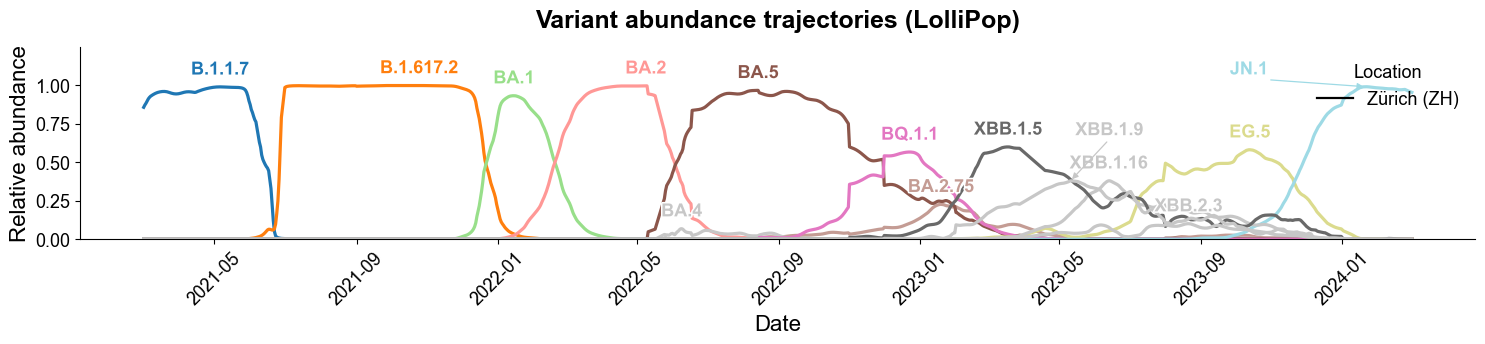

In [6]:
"""
LolliPop variant relative abundances -- same style, size and colours as the NMF abundance panel.
"""


plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

CSV  = '../results/Lollipop_results/deconvolved_sc2.csv'
OUT  = '../results/Lollipop_results/lollipop_abundances.png' 

LOCATION = 'Zürich (ZH)'
DATE_MIN, DATE_MAX = '2021-03-01', '2024-03-01'
THRESHOLD, MIN_DAYS = 0.05, 10          # a variant is drawn if > 5% on at least 10 days
YMAX = 1.25                             # headroom above 100% so displaced labels fit

COLORS = {'B.1.1.7': '#1f77b4', 'B.1.617.2': '#ff7f0e', 'BA.1': '#98df8a', 'BA.2': '#ff9896',
          'BA.5': '#8c564b', 'BQ.1.1': '#e377c2', 'XBB.1.5': 'dimgray', 'EG.5': '#dbdb8d',
          'JN.1': '#9edae5', 'BA.2.75': '#c49c94'}
OTHER = '#c7c7c7'


def place_labels(ax, labels, fontsize=13, pad_pt=2, base_offset=6,
                 dys=tuple(range(6, 130, 12)),
                 dxs=(0, -28, 28, -56, 56, -84, 84, -112, 112),
                 avoid_artists=()):
    """Greedy non-overlapping label placement.
    labels: list of dicts with keys text, x, y, color (peak position in data coords).
    Tallest peaks are placed first; every label takes the closest free offset
    (in points) and gets a leader line if it had to move from the default spot."""
    fig = ax.figure
    fig.canvas.draw()                                  # fixes transforms before measuring
    renderer = fig.canvas.get_renderer()
    pad = pad_pt * fig.dpi / 72
    ax_box = ax.get_window_extent(renderer)

    def padded(b):
        return Bbox.from_extents(b.x0 - pad, b.y0 - pad, b.x1 + pad, b.y1 + pad)

    occupied = [padded(a.get_window_extent(renderer)) for a in avoid_artists]
    candidates = sorted(((dx, dy) for dy in dys for dx in dxs), key=lambda o: np.hypot(*o))
    outline = [pe.withStroke(linewidth=2.2, foreground='white')]

    def make(lab, dx, dy, leader):
        kw = dict(xy=(lab['x'], lab['y']), xytext=(dx, dy), textcoords='offset points',
                  ha='center', va='bottom', fontsize=fontsize, color=lab['color'],
                  fontweight='bold', annotation_clip=False)
        if leader:
            kw['arrowprops'] = dict(arrowstyle='-|>',    
                                    color=lab['color'], lw=0.9,
                                    mutation_scale=9,         # arrowhead size
                                    shrinkA=0, shrinkB=1.5, relpos=(0.5, 0))
        t = ax.annotate(lab['text'], **kw)
        t.set_path_effects(outline)
        return t

    for lab in sorted(labels, key=lambda l: -l['y']):
        chosen = None
        for dx, dy in candidates:
            probe = make(lab, dx, dy, leader=False)    # measured without the leader line
            box = padded(probe.get_window_extent(renderer))
            probe.remove()
            inside = (box.x0 >= ax_box.x0 and box.x1 <= ax_box.x1 and box.y1 <= ax_box.y1)
            if inside and not any(box.overlaps(o) for o in occupied):
                chosen = (dx, dy, box)
                break
        if chosen is None:                              # no free spot: fall back to default
            print(f"warning: no free spot for label {lab['text']}")
            final = make(lab, 0, base_offset, leader=False)
            occupied.append(padded(final.get_window_extent(renderer)))
            continue
        dx, dy, box = chosen
        make(lab, dx, dy, leader=(dx, dy) != (0, base_offset))
        occupied.append(box)


# ── load (fast C parser; delimiter guessed from the header line) ─────────────
with open(CSV, newline='') as fh:
    sep = csv.Sniffer().sniff(fh.readline(), delimiters=',\t;').delimiter
df = pd.read_csv(CSV, sep=sep)
df = df[(df['location'] == LOCATION) & (df['variant'] != 'undetermined')]
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['proportion'] = pd.to_numeric(df['proportion'], errors='coerce')
df = df[(df['date'] >= DATE_MIN) & (df['date'] <= DATE_MAX)].sort_values('date')

# ── plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(18, 2.5))
labels = []
for variant, sub in df.groupby('variant'):
    if (sub['proportion'] > THRESHOLD).sum() < MIN_DAYS:
        continue
    color = COLORS.get(variant, OTHER)
    ax.plot(sub['date'], sub['proportion'], color=color, linewidth=2.3)
    i = sub['proportion'].idxmax()
    labels.append(dict(text=variant, x=sub.at[i, 'date'], y=sub.at[i, 'proportion'], color=color))

ax.set_ylim(0, YMAX)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xlabel('Date', fontsize=16)
ax.set_ylabel('Relative abundance', fontsize=16)
ax.set_title('Variant abundance trajectories (LolliPop)', fontsize=18, fontweight='bold', pad=14)
ax.tick_params(axis='x', rotation=45, labelsize=13)
ax.tick_params(axis='y', labelsize=13)
ax.spines[['top', 'right']].set_visible(False)
leg = ax.legend([plt.Line2D([0], [0], color='black', linewidth=1.6)], [LOCATION],
                title='Location', loc='upper right', fontsize=13, title_fontsize=13, frameon=False)

place_labels(ax, labels, avoid_artists=[leg])           # must come after limits + legend

os.makedirs(os.path.dirname(OUT), exist_ok=True)
fig.savefig(OUT, dpi=300, bbox_inches='tight')
fig.savefig(OUT[:-4] + '.pdf', bbox_inches='tight')
plt.show()

In [19]:
# Ground truth variant signatures

W_covspectrum = pd.read_csv('../resources/variants_definitions_sars/variant_signatures_covspectrum_2026_08_27.csv',
                                       header=0, index_col=0)

variants = W_covspectrum.columns


## Load the data

In [38]:
BASE = Path("../data/joint_input")
LOCATIONS = ["ZH"]

raw = {}
passing = {}
for loc in LOCATIONS:
    A = pd.read_csv(BASE / loc / "datamatrix_snvs.csv", header=0, index_col=0)
    A.columns = pd.to_datetime(A.columns, format='%Y_%m_%d')
    #A = A.loc[:, (A.columns >= pd.Timestamp('2022-11-01')) & (A.columns <= pd.Timestamp('2023-03-01'))]
    raw[loc] = A
    passing[loc] = A.index[(A >= 0.05).sum(axis=1) >= 10]   # this location's own reliably-present rows

union_index = sorted(set().union(*passing.values()))
print(f"{len(union_index)} mutations pass the filter in at least one location")

data = {}
for loc in LOCATIONS:
    A_loc = raw[loc].reindex(union_index)             # NaN for mutations this location's CSV never had at all
    fails_here = ~A_loc.index.isin(passing[loc])        # rows that didn't clear THIS location's own filter

    data[loc] = A_loc

    print(loc, data[loc].shape, "failed mutations for specific location", fails_here.sum())



1136 mutations pass the filter in at least one location
ZH (1136, 972) failed mutations for specific location 0


## Generate the window-datasets for real time detection (CROSS VALIDATION)

In [13]:
# OUT_DIR = Path("cv_datasets_early_detection")
# MIN_WINDOW, TRAIN_STEP, FORECAST_HORIZON = 60, 1, 7       # same as the experiment config

# # copied from the experiment config -- keep in sync
# STEP_DATE_WINDOWS = {
#     'B.1.617.2': ('2021-03-01', '2021-09-01'),
#     'BA.1':      ('2021-09-01', '2022-02-01'),
#     'BA.2':      ('2021-10-01', '2022-04-15'),
#     'BA.5':      ('2022-03-01', '2022-09-01'),
#     'BQ.1.1':    ('2022-08-01', '2023-01-01'),
#     'XBB.1.5':   ('2022-09-01', '2023-03-01'),
# }

# data_sorted = {loc: df.sort_index(axis=1) for loc, df in data.items()}   # same as main()

# for target, (start, end) in STEP_DATE_WINDOWS.items():
#     # this era's data: the window filter from main()
#     data_step = {}
#     for loc, df in data_sorted.items():
#         cols = pd.to_datetime(df.columns)
#         data_step[loc] = df.loc[:, (cols >= pd.to_datetime(start)) & (cols <= pd.to_datetime(end))]
#     dates = {loc: pd.to_datetime(df.columns) for loc, df in data_step.items() if df.shape[1] > 0}
#     if not dates:
#         print(f"{target}: no samples in window, skipped")
#         continue

#     origin = min(d.min() for d in dates.values())
#     last_date = max(d.max() for d in dates.values())

#     cutoff = origin + pd.Timedelta(days=MIN_WINDOW)
#     n_saved = 0
#     while cutoff <= last_date:
#         forecast_cutoff = cutoff + pd.Timedelta(days=FORECAST_HORIZON)
#         train_window, has_target = {}, False
#         for loc, d in dates.items():
#             train_mask = d <= cutoff
#             if train_mask.sum() < 2:
#                 continue                                   # location not trained yet at this cutoff
#             train_window[loc] = data_step[loc].loc[:, train_mask]
#             if (d >= forecast_cutoff).any():
#                 has_target = True                          # something to forecast -> the experiment fits here
#         if train_window and has_target:
#             folder = OUT_DIR / target / cutoff.strftime('%Y-%m-%d')
#             folder.mkdir(parents=False, exist_ok=True)
#             for loc, sub in train_window.items():
#                 sub = sub.copy()
#                 sub.columns = pd.to_datetime(sub.columns).strftime('%Y_%m_%d')
#                 sub.to_csv(folder / f"{loc}.csv")
#             n_saved += 1
#         cutoff += pd.Timedelta(days=TRAIN_STEP)
#     print(f"{target}: {n_saved} datasets saved")

In [8]:
# estimate % of missing values
data_zh = data["ZH"].copy()

is_missing = data_zh.isna().sum().sum() / data_zh.size
print(is_missing)

0.14038500550628877


## Apply FitNMF on single location (Zurich)

In [39]:
result_fitness = joint_soft_dynamics_nmf(
    data,# {'ZH': data['ZH']},
    masking_option=0,
    rank=10,
    rel_tol=1e-4,
    lambda_w=0.01,
    lambda_h=0.1,
    lambda_f=5,
    bandwidth=10.0,
    n_run=10,
    random_state=42,
    n_jobs = 4,
    n_mu_steps = 1,
    n_half_frac=0.1

)


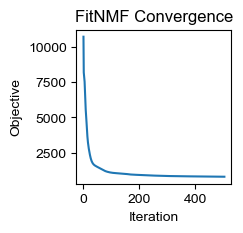

In [40]:
plt.figure(figsize=(2,2))

plt.plot(result_fitness.objective_values)
plt.xlabel("Iteration")
plt.ylabel("Objective")
plt.title("FitNMF Convergence")
plt.show()

In [49]:
# %load_ext autoreload
# %autoreload 2
# from evaluation.plot_joint_matched_heatmap import plot_matched_heatmap_and_abundances
import importlib

import evaluation.fig3_growth_advantages as pjmh
importlib.reload(pjmh)
from evaluation.fig3_growth_advantages import make_figure3

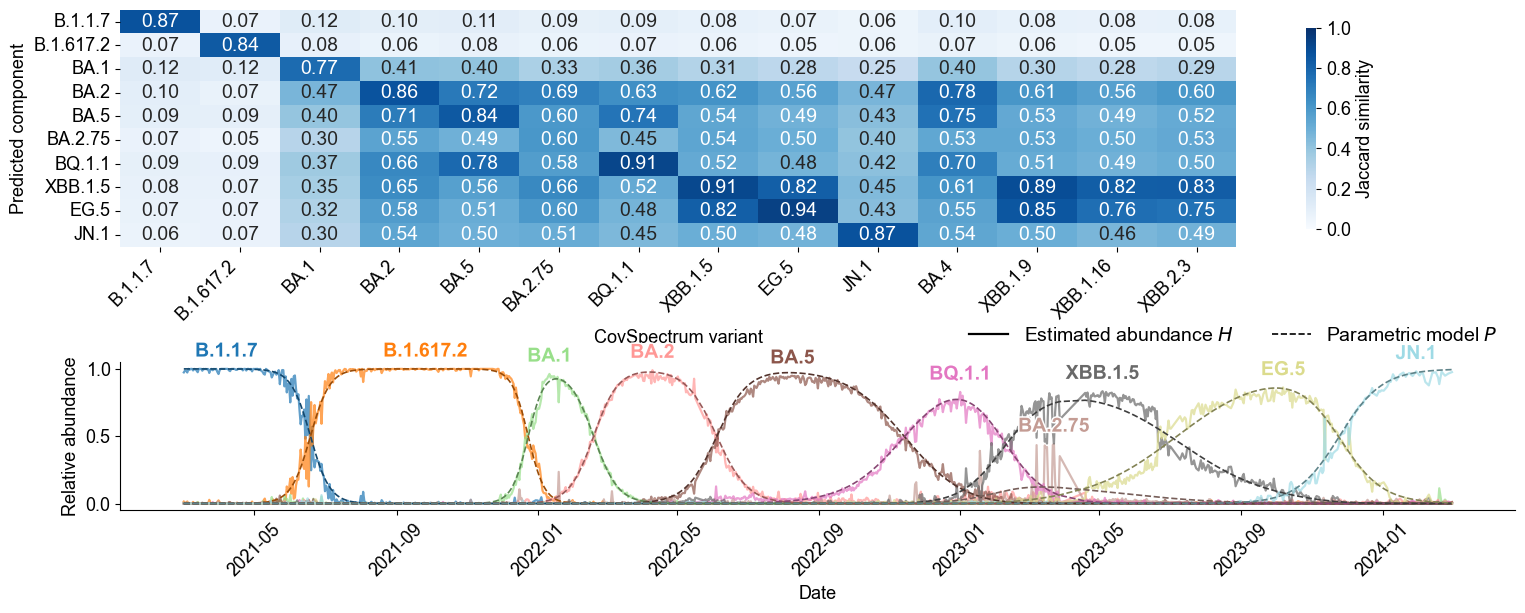

In [41]:
fig = plot_matched_heatmap_and_abundances(result_fitness, data, W_covspectrum, out_path='../results/real_data/single_location_matched_results_ZH_nmf_fitness.png', tie_tol=0.01)

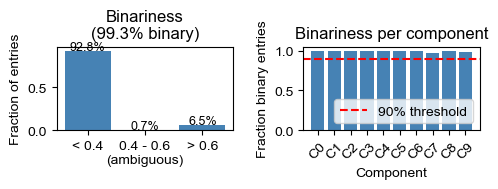

In [27]:
# ── Usage ─────────────────────────────────────────────────────────────────────
plot_binariness(result_fitness.W_unnormalized, title='Binariness of W — FitNMF')

# Apply FitNMF on multiple locations (6 WWTPs)

In [30]:
BASE = Path("../data/joint_input")
LOCATIONS = ["ZH", "GR", "BE", "GE", "SG", "TI"]

raw = {}
passing = {}
for loc in LOCATIONS:
    A = pd.read_csv(BASE / loc / "datamatrix_snvs.csv", header=0, index_col=0)
    A.columns = pd.to_datetime(A.columns, format='%Y_%m_%d')
    #A = A.loc[:, (A.columns >= pd.Timestamp('2022-11-01')) & (A.columns <= pd.Timestamp('2023-03-01'))]
    raw[loc] = A
    passing[loc] = A.index[(A >= 0.05).sum(axis=1) >= 10]   # this location's own reliably-present rows

union_index = sorted(set().union(*passing.values()))
print(f"{len(union_index)} mutations pass the filter in at least one location")

data = {}
for loc in LOCATIONS:
    A_loc = raw[loc].reindex(union_index)             # NaN for mutations this location's CSV never had at all
    fails_here = ~A_loc.index.isin(passing[loc])        # rows that didn't clear THIS location's own filter

    data[loc] = A_loc

    print(loc, data[loc].shape, "failed mutations for specific location", fails_here.sum())



2038 mutations pass the filter in at least one location
ZH (2038, 972) failed mutations for specific location 902
GR (2038, 961) failed mutations for specific location 893
BE (2038, 939) failed mutations for specific location 963
GE (2038, 793) failed mutations for specific location 1205
SG (2038, 958) failed mutations for specific location 804
TI (2038, 949) failed mutations for specific location 1065


In [31]:
result = joint_soft_dynamics_nmf(
    data,
    rank=10,
    masking_option=0,        # 0=free, 1=soft pull toward Q, 2=hard clamp to Q
    rel_tol=1e-4,
    lambda_w=0.01,
    lambda_h=0.1,
    lambda_f=5,
    n_run=10,                 # random restarts, keeps best final objective
    n_jobs=4,                 # parallelize restarts across cores
    random_state=42,           # for reproducibility
    n_mu_steps = 1,
    n_half_frac=0.1

)

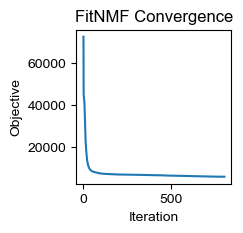

In [32]:
plt.figure(figsize=(2,2))

plt.plot(result.objective_values)
plt.xlabel("Iteration")
plt.ylabel("Objective")
plt.title("FitNMF Convergence")
plt.show()

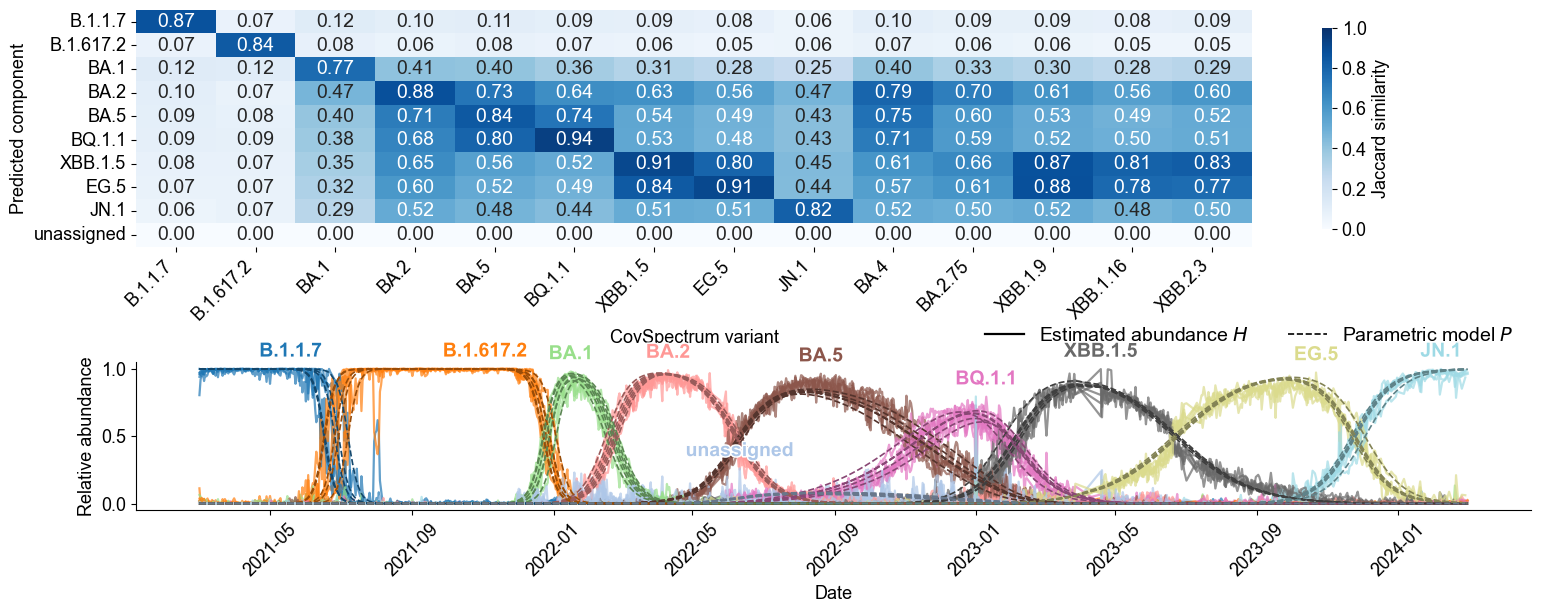

In [33]:
fig = plot_matched_heatmap_and_abundances(result, data, W_covspectrum,
                                        out_path='../results/real_data/multiple_location_matched_results_joint_nmf_fitness.png', tie_tol=0.01)

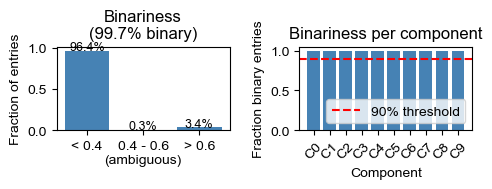

In [34]:
plot_binariness(result.W_unnormalized, title='Binariness of W — FitNMF')

# Early detection experiment. ZH WWTP

In [17]:
BASE = Path("../data/joint_input")
LOCATIONS = ["ZH"]

raw = {}
passing = {}
for loc in LOCATIONS:
    A = pd.read_csv(BASE / loc / "datamatrix_snvs.csv", header=0, index_col=0)
    A.columns = pd.to_datetime(A.columns, format='%Y_%m_%d')
    #A = A.loc[:, (A.columns >= pd.Timestamp('2022-11-01')) & (A.columns <= pd.Timestamp('2023-03-01'))]
    raw[loc] = A
    passing[loc] = A.index[(A >= 0.05).sum(axis=1) >= 10]   # this location's own reliably-present rows

union_index = sorted(set().union(*passing.values()))
print(f"{len(union_index)} mutations pass the filter in at least one location")

data = {}
for loc in LOCATIONS:
    A_loc = raw[loc].reindex(union_index)             # NaN for mutations this location's CSV never had at all
    fails_here = ~A_loc.index.isin(passing[loc])        # rows that didn't clear THIS location's own filter

    data[loc] = A_loc

    print(loc, data[loc].shape, "failed mutations for specific location", fails_here.sum())



1136 mutations pass the filter in at least one location
ZH (1136, 972) failed mutations for specific location 0


[step 1] known: B.1.1.7 -> target: B.1.617.2
[step 2] known: B.1.617.2 -> target: BA.1
[step 3] known: B.1.617.2, BA.1 -> target: BA.2
[step 4] known: BA.2, BA.4 -> target: BA.5
[step 5] known: BA.4, BA.5, BA.2.75 -> target: BQ.1.1
[step 6] known: BA.5, BA.2.75, BQ.1.1 -> target: XBB.1.5


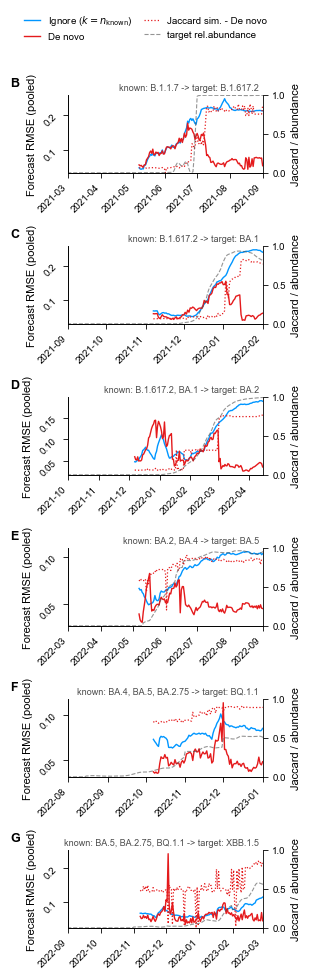


Per-step summary:
  known: B.1.1.7 -> target: B.1.617.2:
    de novo better than ignore in 75% of windows (mean pooled RMSE improvement +0.0773)
  known: B.1.617.2 -> target: BA.1:
    de novo better than ignore in 80% of windows (mean pooled RMSE improvement +0.0555)
  known: B.1.617.2, BA.1 -> target: BA.2:
    de novo better than ignore in 72% of windows (mean pooled RMSE improvement +0.0422)
  known: BA.2, BA.4 -> target: BA.5:
    de novo better than ignore in 94% of windows (mean pooled RMSE improvement +0.0357)
  known: BA.4, BA.5, BA.2.75 -> target: BQ.1.1:
    de novo better than ignore in 99% of windows (mean pooled RMSE improvement +0.0277)
  known: BA.5, BA.2.75, BQ.1.1 -> target: XBB.1.5:
    de novo better than ignore in 79% of windows (mean pooled RMSE improvement +0.0111)


In [31]:
ERA_SEQUENCE      = ['B.1.1.7', 'B.1.617.2', 'BA.1', 'BA.2', 'BA.4', 'BA.5', 'BQ.1.1', 'BA.2.75', 'XBB.1.5']

MIN_WINDOW        = 60
TRAIN_STEP        = 1
FORECAST_HORIZON  = 7
BANDWIDTH         = 10
N_RUN             = 10

# Best hyperparameters per (target, cutoff), from the per-window CV (Snakemake summary)
BEST_HP_CSV = "../results/cross_validation_results/windows_ZH_real_time_detection/cross_validation_best_by_window_snv.csv"

STEP_DATE_WINDOWS = {
    'B.1.617.2': ('2021-03-01', '2021-09-01'),
    'BA.1':       ('2021-09-01', '2022-02-01'),
    'BA.2':       ('2021-10-01', '2022-04-15'),
    'BA.5':       ('2022-03-01', '2022-09-01'),
    'BQ.1.1':       ('2022-08-01', '2023-01-01'),
    'XBB.1.5':       ('2022-09-01', '2023-03-01'),
}

# known variants from clinical data at eeach step
STEP_MASKED_VARIANTS = {
    'B.1.617.2': ['B.1.1.7'],
    'BA.1':      ['B.1.617.2'],
    'BA.2':      ['B.1.617.2', 'BA.1'],
    'BA.5':      ['BA.2', 'BA.4'],
    'BQ.1.1':      ['BA.4', 'BA.5', 'BA.2.75'],
    'XBB.1.5':      ['BA.5', 'BA.2.75', 'BQ.1.1'],
}
NUMBER_OF_VARIANTS = {  # for the de novo setting
    'B.1.617.2': 2,
    'BA.1': 2,
    'BA.2': 3,
    'BA.5': 3,
    'BQ.1.1': 4,
    'XBB.1.5': 4,
}

# ── Lollipop ground-truth abundances ────────────────────────────────────────

LOLLIPOP_CSV = '../results/Lollipop_results/deconvolved_sc2.csv'
LOLLIPOP_LOCATION_MAP = {'ZH': 'Zürich (ZH)'}      # must match the location names inside the CSV

_LOLLIPOP_DF = None



# Each model gets one color, used for both its RMSE line (solid) and its
# Jaccard-to-target line (dotted) -- so line style alone tells you which
# metric, and color alone tells you which model.
COL_IGNORE  = '#0096FF'   # bright blue
COL_LEARN   = '#2CA02C'   # green
COL_DENOVO  = '#E41A1C'   # red
COL_TRUTH   = '#4D4D4D'   # neutral grey

mpl.rcParams.update({
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size':          8,
    'axes.titlesize':     8,
    'axes.labelsize':     8,
    'xtick.labelsize':    7,
    'ytick.labelsize':    7,
    'legend.fontsize':    7,
    'axes.linewidth':     0.6,
    'xtick.major.width':  0.6,
    'ytick.major.width':  0.6,
    'lines.linewidth':    1.0,
    'savefig.dpi':        600,
    'pdf.fonttype':       42,
    'ps.fonttype':        42,
})


_LOLLIPOP_DF = None


def _load_lollipop_df(path=LOLLIPOP_CSV):
    """Returns a long DataFrame with columns location, variant, date, proportion.
    Accepts a long file (columns variant + proportion) or a wide file (one column per variant);
    the separator (comma / tab) is detected."""
    global _LOLLIPOP_DF
    if _LOLLIPOP_DF is not None:
        return _LOLLIPOP_DF

    raw = pd.read_csv(path, sep=None, engine='python')
    low = {c.lower(): c for c in raw.columns}

    date_col = next((low[c] for c in ('date', 'sampling_date', 'sample_date') if c in low), None)
    if date_col is None:
        raise KeyError(f"no date column in {path}; columns: {list(raw.columns)}")
    loc_col = next((low[c] for c in ('location', 'loc', 'site', 'plant') if c in low), None)

    if 'variant' in low and 'proportion' in low:                      # long format
        df = raw.rename(columns={low['variant']: 'variant', low['proportion']: 'proportion'})
    else:                                                             # wide format: one column per variant
        id_cols = [date_col] + ([loc_col] if loc_col else [])
        skip = ('lower', 'upper', 'ci_', 'sample', 'n_', 'index', 'unnamed')
        value_cols = [c for c in raw.columns
                      if c not in id_cols and pd.api.types.is_numeric_dtype(raw[c])
                      and not any(s in c.lower() for s in skip)]
        df = raw.melt(id_vars=id_cols, value_vars=value_cols, var_name='variant', value_name='proportion')
        df['variant'] = df['variant'].str.replace(r'^proportion[_ ]', '', regex=True)

    df = df.rename(columns={date_col: 'date'})
    df['date'] = pd.to_datetime(df['date'])
    df['location'] = df[loc_col] if loc_col else 'ALL'
    _LOLLIPOP_DF = (df[['location', 'variant', 'date', 'proportion']]
                    .sort_values(['location', 'variant', 'date']).reset_index(drop=True))
    return _LOLLIPOP_DF


def get_true_abundance_from_lollipop(target_variant, location):
    df = _load_lollipop_df()
    if location not in set(df['location']) and set(df['location']) == {'ALL'}:
        sub = df                                                       # file has no location column
    else:
        sub = df[df['location'] == location]
    sub = sub[sub['variant'] == target_variant]
    if sub.empty:
        print(f"  WARNING: no Lollipop data for variant={target_variant!r}, location={location!r}. "
              f"Variants: {sorted(df['variant'].unique())[:15]} ...  Locations: {sorted(df['location'].unique())[:10]}")
    return sub.groupby('date')['proportion'].mean().sort_index()       # mean over duplicate dates


# ── Hyperparameters chosen by per-window cross-validation ───────────────────

def load_best_hp(path=BEST_HP_CSV):
    """{(target, 'YYYY-MM-DD'): dict(lambda_w, lambda_h, lambda_f)}, lowest CV error per window.
    Works for a file with one row per window and for the full per-combination summary."""
    df = pd.read_csv(path)
    need = {'target', 'cutoff', 'lambda_w', 'lambda_h', 'lambda_f'}
    if not need <= set(df.columns):
        raise KeyError(f"{path} needs columns {sorted(need)}; found {list(df.columns)}")
    # cutoff may be 'YYYY-MM-DD' or 'DD.MM.YYYY' (e.g. after the file was opened/saved in Excel); parse each
    # format explicitly, never guess day/month order
    c = df['cutoff'].astype(str).str.strip()
    parsed = pd.to_datetime(c, format='%Y-%m-%d', errors='coerce')
    parsed = parsed.fillna(pd.to_datetime(c, format='%d.%m.%Y', errors='coerce'))
    if parsed.isna().any():
        raise ValueError(f"unrecognised cutoff format, e.g. {c[parsed.isna()].iloc[0]!r}")
    df['cutoff'] = parsed.dt.strftime('%Y-%m-%d')

    if 'mean_error' in df.columns:
        df = df.sort_values('mean_error')
    best = df.groupby(['target', 'cutoff'], as_index=False).first()
    return {(r.target, r.cutoff): dict(lambda_w=float(r.lambda_w), lambda_h=float(r.lambda_h),
                                       lambda_f=float(r.lambda_f))
            for r in best.itertuples()}


# ── Model fitting -- joint across locations ─────────────────────────────────

def fit_model_joint(data_window, W_aligned, known_variants, **nmf_kwargs):
    """'Ignore' model: W columns pinned to the known signatures (masking_option=2), k = n_known."""
    n_known = len(known_variants)
    Q = W_aligned[known_variants].values.astype(float)
    Q_mask = np.ones_like(Q)
    result = joint_soft_dynamics_nmf(
        data_window, rank=n_known, masking_option=2,
        Q=Q, Q_mask=Q_mask, **nmf_kwargs)
    return result, n_known





def fit_model_denovo_joint(data_window, rank, **nmf_kwargs):
    """Fully unconstrained joint NMF -- no known-variant pinning at all."""
    result = joint_soft_dynamics_nmf(
        data_window, rank=rank, masking_option=0,**nmf_kwargs)
    return result


# ── Jaccard helpers ───────────

def free_column_jaccard(result, W_aligned, target_variant, n_known):
    """Jaccard between the (binarized) free column and the target's true
    signature. Assumes column index n_known is the single unpinned column."""
    if result.W.shape[1] <= n_known:
        return np.nan
    free_col_idx = n_known
    W_free = binarize_signature_matrix(result.W[:, [free_col_idx]])
    W_t = binarize_signature_matrix(W_aligned[[target_variant]].values)
    dist = cdist(W_free.T, W_t.T, metric='jaccard')
    return float(1 - dist[0, 0])


def denovo_target_jaccard_hungarian(result, W_aligned, known_variants, target_variant):
    """Jaccard between the target's true signature and its Hungarian-
    assigned predicted column, for a fully unconstrained ("de novo") fit."""
    gt_variants = list(known_variants) + [target_variant]
    target_idx = len(known_variants)

    W_pred = binarize_signature_matrix(result.W)
    W_gt = binarize_signature_matrix(W_aligned[gt_variants].values)

    dist = cdist(W_pred.T, W_gt.T, metric='jaccard')
    sim = 1 - dist

    row_ind, col_ind = linear_sum_assignment(-sim)
    assigned = dict(zip(col_ind, sim[row_ind, col_ind]))
    return float(assigned.get(target_idx, np.nan))


# ── Comparison loop -- joint across locations ───────────────────────────────

def run_comparison_joint(data_dict, W_aligned, known_variants, target_variant,
                          min_window=MIN_WINDOW, train_step=TRAIN_STEP,
                          horizon=FORECAST_HORIZON, denovo_rank=None,
                          hp_by_cutoff=None, **nmf_kwargs):
    """
    hp_by_cutoff: {'YYYY-MM-DD': dict(lambda_w, lambda_h, lambda_f)} -- hyperparameters selected by
    K-fold CV on exactly the training window of that cutoff. A cutoff without an entry is skipped
    (with a warning), so no fit silently runs with untuned values. The fixed-W ("ignore") model gets
    the same lambda_h / lambda_f (its W is pinned, so lambda_w has no effect).
    """
    locations = list(data_dict.keys())
    parsed = {loc: _parse_dates(data_dict[loc]) for loc in locations}
    sorted_data = {loc: parsed[loc][0] for loc in locations}   # DataFrame, Timestamp columns, sorted
    dates = {loc: parsed[loc][1] for loc in locations}         # DatetimeIndex per location

    origin = min(d.min() for d in dates.values() if len(d))
    last_date = max(d.max() for d in dates.values() if len(d))

    n_known = len(known_variants)
    rank_denovo = denovo_rank or n_known + 1                   # same rank as in the CV

    records, missing_hp = [], []
    cutoff = origin + pd.Timedelta(days=min_window)

    while cutoff <= last_date:
        forecast_cutoff = cutoff + pd.Timedelta(days=horizon)

        train_window, actual, M, t_future = {}, {}, {}, {}
        for loc in locations:
            loc_dates = dates[loc]
            train_mask = (loc_dates <= cutoff)   # DatetimeIndex comparison -> plain ndarray already
            if train_mask.sum() < 2:
                continue   # not enough history at this location yet -- excluded from THIS window's fit

            train_window[loc] = sorted_data[loc].loc[:, train_mask]

            future_mask = (loc_dates > cutoff)
            future_dates = loc_dates[future_mask]
            eligible = future_dates[future_dates >= forecast_cutoff]
            if len(eligible) == 0:
                continue   # trained on this location, but nothing to score yet
            forecast_date = eligible.min()

            score_mask = future_mask & (loc_dates <= forecast_date)
            actual_loc = sorted_data[loc].loc[:, score_mask].values
            actual[loc] = actual_loc
            M[loc] = (~np.isnan(actual_loc)).astype(float)

            score_dates = pd.to_datetime(sorted_data[loc].columns[score_mask])
            t_future[loc] = (score_dates - origin).days.to_numpy(dtype=float)

        if len(train_window) == 0:
            cutoff += pd.Timedelta(days=train_step)
            continue

        if len(actual) == 0:
            cutoff += pd.Timedelta(days=train_step)
            continue

        # Hyperparameters selected by CV on exactly this training window (data up to `cutoff` only)
        fit_kwargs = dict(nmf_kwargs)
        if hp_by_cutoff is not None:
            hp = hp_by_cutoff.get(cutoff.strftime('%Y-%m-%d'))
            if hp is None:
                missing_hp.append(cutoff.strftime('%Y-%m-%d'))
                cutoff += pd.Timedelta(days=train_step)
                continue
            fit_kwargs.update(hp)

        def score(result):
            """Pools squared masked residuals across every location that
            has a valid forecast target this window into ONE RMSE (so the
            record shape matches the single-location script), and also
            returns the per-location breakdown for diagnostic use."""
            total_sq, total_n = 0.0, 0.0
            per_loc = {}
            for loc in actual:
                H_forecast = compute_p(result.f, result.b[loc], t_future[loc])
                A_forecast = (result.W) @ H_forecast 
                if M[loc].sum() == 0:
                    per_loc[loc] = np.nan
                    continue
                diff = (A_forecast - np.where(np.isnan(actual[loc]), 0.0, actual[loc])) * M[loc]
                sq = np.sum(diff ** 2)
                total_sq += sq
                total_n += M[loc].sum()
                per_loc[loc] = float(np.sqrt(sq / M[loc].sum()))
            pooled = float(np.sqrt(total_sq / total_n)) if total_n > 0 else np.nan
            return pooled, per_loc

        if n_known >= 1:
            result_ignore, _ = fit_model_joint(train_window, W_aligned, known_variants, **fit_kwargs)
            rmse_ignore, rmse_ignore_by_loc = score(result_ignore)
        else:
            rmse_ignore, rmse_ignore_by_loc = np.nan, {}

        result_denovo = fit_model_denovo_joint(train_window, rank=rank_denovo, **fit_kwargs)

        rmse_denovo, rmse_denovo_by_loc = score(result_denovo)
        jaccard_denovo = denovo_target_jaccard_hungarian(result_denovo, W_aligned, known_variants, target_variant)

        records.append({
            # cutoff/forecast_cutoff are the SCHEDULING dates (deterministic,
            # data-independent), used here instead of "the actual last
            # sample date used" since with multiple locations there's no
            # single such date anymore -- every location snaps to its own
            # nearest sample around these two scheduling points.
            'train_end_date':    cutoff,
            'forecast_end_date': forecast_cutoff,
            'n_locations_trained': len(train_window),
            'n_locations_scored':  len(actual),
            'rmse_ignore': rmse_ignore,
            'rmse_denovo': rmse_denovo,
            'denovo_better_than_ignore': (rmse_denovo < rmse_ignore
                                if np.isfinite(rmse_ignore) and np.isfinite(rmse_denovo) else None),
            'denovo_best_jaccard_to_target': jaccard_denovo,
            'rmse_ignore_by_loc': rmse_ignore_by_loc,
            'rmse_denovo_by_loc': rmse_denovo_by_loc,
            # hyperparameters used at this cutoff
            'lambda_w': fit_kwargs.get('lambda_w'),
            'lambda_h': fit_kwargs.get('lambda_h'),
            'lambda_f': fit_kwargs.get('lambda_f'),
        })

        cutoff += pd.Timedelta(days=train_step)

    if missing_hp:
        print(f"  WARNING [{target_variant}]: no CV hyperparameters for {len(missing_hp)} cutoff(s), skipped: "
              f"{missing_hp[:3]}{' ...' if len(missing_hp) > 3 else ''}")

    return records



def main():
    """
    `data` is now expected to be a dict[location] -> DataFrame (the same
    convention joint_soft_dynamics_nmf itself uses), with every
    location's rows ALREADY aligned to a common (unioned) mutation index --
    see the earlier union/NaN-fill data-loading step. This is checked
    explicitly below rather than assumed silently, since a mismatch here
    wouldn't raise on its own downstream -- it would just silently
    misalign which mutation each row of the shared W refers to.

    """
    locations = list(data.keys())
    mutation_index = data[locations[0]].index
    for loc in locations[1:]:
        if not data[loc].index.equals(mutation_index):
            raise ValueError(
                f"location {loc!r}'s row index doesn't match {locations[0]!r}'s -- "
                f"every location must share the same (unioned) mutation row index "
                f"before fitting a shared W across them.")

    data_sorted = {loc: df.sort_index(axis=1) for loc, df in data.items()}
    #W_aligned_full_non_binary = W_covspectrum_non_binary.reindex(mutation_index, fill_value=0)
    W_aligned_full= W_covspectrum.reindex(mutation_index, fill_value=0)


    missing = [v for v in ERA_SEQUENCE if v not in W_aligned_full.columns]
    if missing:
        raise KeyError(
            f"W_covspectrum is missing signature definitions for {missing} -- "
            f"fetch/add these lineages before running this script.")

    # lambda_w / lambda_h / lambda_f are NOT set here: they come from the per-window CV (hp_by_cutoff)
    nmf_kwargs = dict(rel_tol=1e-4, bandwidth=BANDWIDTH, n_run=N_RUN,
                       random_state=42, n_jobs=-1)
    best_hp = load_best_hp()

    all_records, step_labels, target_variants, true_abundances, step_windows = [], [], [], [], []
    TARGET_VARIANTS = [v for v in ERA_SEQUENCE if v in STEP_DATE_WINDOWS]

    for step_num, target_variant in enumerate(TARGET_VARIANTS, start=1):
        idx = ERA_SEQUENCE.index(target_variant)
        known_variants = STEP_MASKED_VARIANTS.get(target_variant, ERA_SEQUENCE[:idx])
        denovo_rank = NUMBER_OF_VARIANTS.get(target_variant, len(known_variants) + 1)
        step_label = f"known: {', '.join(known_variants)} -> target: {target_variant}"
        print(f"[step {step_num}] {step_label}")

        window = STEP_DATE_WINDOWS.get(target_variant)
        if window is not None:
            start, end = window
            data_step = {
                loc: df.loc[:, (pd.to_datetime(df.columns) >= start) & (pd.to_datetime(df.columns) <= end)]
                for loc, df in data_sorted.items()
            }
            step_window = (pd.to_datetime(start), pd.to_datetime(end))
        else:
            data_step = data_sorted
            all_dates = pd.concat([pd.Series(pd.to_datetime(df.columns)) for df in data_sorted.values()])
            step_window = (all_dates.min(), all_dates.max())

        hp_by_cutoff = {c: hp for (t, c), hp in best_hp.items() if t == target_variant}
        if not hp_by_cutoff:
            raise KeyError(f"no CV results for target {target_variant!r} in {BEST_HP_CSV}")

        records = run_comparison_joint(
            data_step, W_aligned_full, known_variants, target_variant,
            denovo_rank=denovo_rank, hp_by_cutoff=hp_by_cutoff, **nmf_kwargs)

        all_records.append(records)
        step_labels.append(step_label)
        target_variants.append(target_variant)
        true_abundances.append({
            loc: get_true_abundance_from_lollipop(target_variant, LOLLIPOP_LOCATION_MAP.get(loc, loc))
            for loc in locations
        })
        step_windows.append(step_window)

    # ── Summary ──────────────────────────────────────────────────────────────
    rows = []
    for step_label, target_variant, records in zip(step_labels, target_variants, all_records):
        for r in records:
            row = dict(step=step_label, target=target_variant, **r)
            for key in ('rmse_ignore_by_loc', 'rmse_denovo_by_loc'):
                row[key] = json.dumps(row[key])
            rows.append(row)
    summary = pd.DataFrame(rows)
    summary.to_csv('../results/real_data/forecast_emergence_chain_joint_errors.csv', index=False)


    print("\nPer-step summary:")
    for step_label, target_variant in zip(step_labels, target_variants):
        sub = summary[summary['target'] == target_variant].dropna(subset=['denovo_better_than_ignore'])
        if len(sub) == 0:
            print(f"  {step_label}: no comparable windows"); continue
        win  = sub['denovo_better_than_ignore'].astype(bool).mean()
        diff = (sub['rmse_ignore'] - sub['rmse_denovo']).mean()
        print(f"  {step_label}:\n    de novo better than ignore in {win:.0%} of windows "
              f"(mean pooled RMSE improvement {diff:+.4f})")

    return all_records, step_labels, target_variants, true_abundances, step_windows


if __name__ == '__main__':
    all_records, step_labels, target_variants, true_abundances, step_windows = main()

In [47]:
def make_publication_figure(all_records, step_labels, target_variants, true_abundances,
                             step_windows, out_stem='../results/real_data/forecast_emergence_chain_figure_4',
                             ncols=3, fig_width_in=6.0, panel_height_in=1.5):
    """Panels laid out in a grid (default 3 per row, full text width). Y-axis labels only on the outer columns."""
    n_panels = len(all_records)
    nrows = int(np.ceil(n_panels / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(fig_width_in, panel_height_in * nrows), squeeze=False)
    axes_flat = axes.ravel()
    for ax in axes_flat[n_panels:]:
        ax.set_visible(False)

    panel_letters = [chr(ord('A') + i) for i in range(n_panels)]
    legend_handles, legend_labels = None, None

    for i, (ax, records) in enumerate(zip(axes_flat, all_records)):
        col = i % ncols
        true_abundance = true_abundances[i]
        window_start, window_end = step_windows[i]
        fd = [r['train_end_date'] for r in records]

        fe = [r['forecast_end_date'] for r in records]                    # new: used by the RMSE lines

        h1, = ax.plot(fe, [r['rmse_ignore'] for r in records],
                    color=COL_IGNORE, label='FitNMF: fixed W')
        h5, = ax.plot(fe, [r['rmse_denovo'] for r in records], color=COL_DENOVO, label='FitNMF: De novo')

        if col == 0:
            ax.set_ylabel('Forecast RMSE (pooled)')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        ax2 = ax.twinx()
        h6, = ax2.plot(fd, [r['denovo_best_jaccard_to_target'] for r in records],
                       color=COL_DENOVO, linestyle=':', linewidth=0.9, label='Jaccard sim.')
        handles = [h1, h5, h6]

        if true_abundance is not None:
            truth_items = true_abundance.items() if isinstance(true_abundance, dict) \
                else [(None, true_abundance)]
            first = True
            for loc, series in truth_items:
                if series is None or len(series) == 0:
                    continue
                h4, = ax2.plot(series.index, series.values, color=COL_TRUTH, linestyle='--', linewidth=0.8,
                               alpha=0.6, label='target rel.abundance' if first else None)
                if first:
                    handles.append(h4)
                    first = False

        ax2.set_ylim(0, 1)
        if col == ncols - 1 or i == n_panels - 1:
            ax2.set_ylabel('Jaccard / abundance')
        else:
            ax2.tick_params(labelright=False)        # same 0-1 scale in every panel: label it on the right-most column
        ax2.spines['top'].set_visible(False)
        ax2.tick_params(direction='out')

        for a in (ax, ax2):
            a.set_autoscalex_on(False)
            a.set_xlim(window_start, window_end)
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %y'))
        ax.tick_params(direction='out')
        plt.setp(ax.get_xticklabels(), rotation=45, ha='right')

        known, target = step_labels[i].split(' -> ')
        ax.text(0.0, 1.04, panel_letters[i], transform=ax.transAxes, fontsize=9, fontweight='bold',
                va='bottom', ha='left')
        ax.text(1.0, 1.04, f"{known}\n{target}", transform=ax.transAxes, fontsize=6, ha='right',
                va='bottom', color='0.3', linespacing=1.1)

        if i == 0:
            legend_handles, legend_labels = handles, [h.get_label() for h in handles]

    fig.legend(legend_handles, legend_labels, loc='upper center', bbox_to_anchor=(0.5, 1.03), ncol=4,
               frameon=False, handlelength=1.6, columnspacing=1.2)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    fig.savefig(f'{out_stem}.pdf', bbox_inches='tight')
    plt.show()

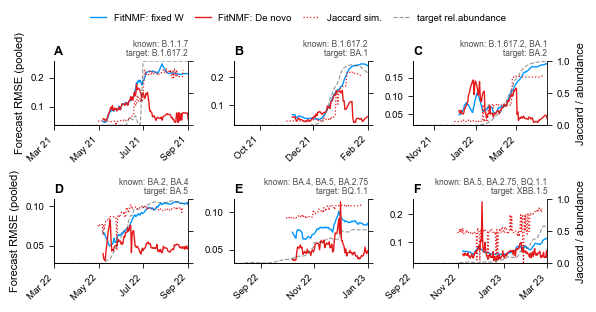

In [48]:
true_abundances = [{loc: get_true_abundance_from_lollipop(t, LOLLIPOP_LOCATION_MAP.get(loc, loc))
                    for loc in ['ZH']} for t in target_variants]
make_publication_figure(all_records, step_labels, target_variants, true_abundances, step_windows)

# Compare fitness estimates with Covvfit

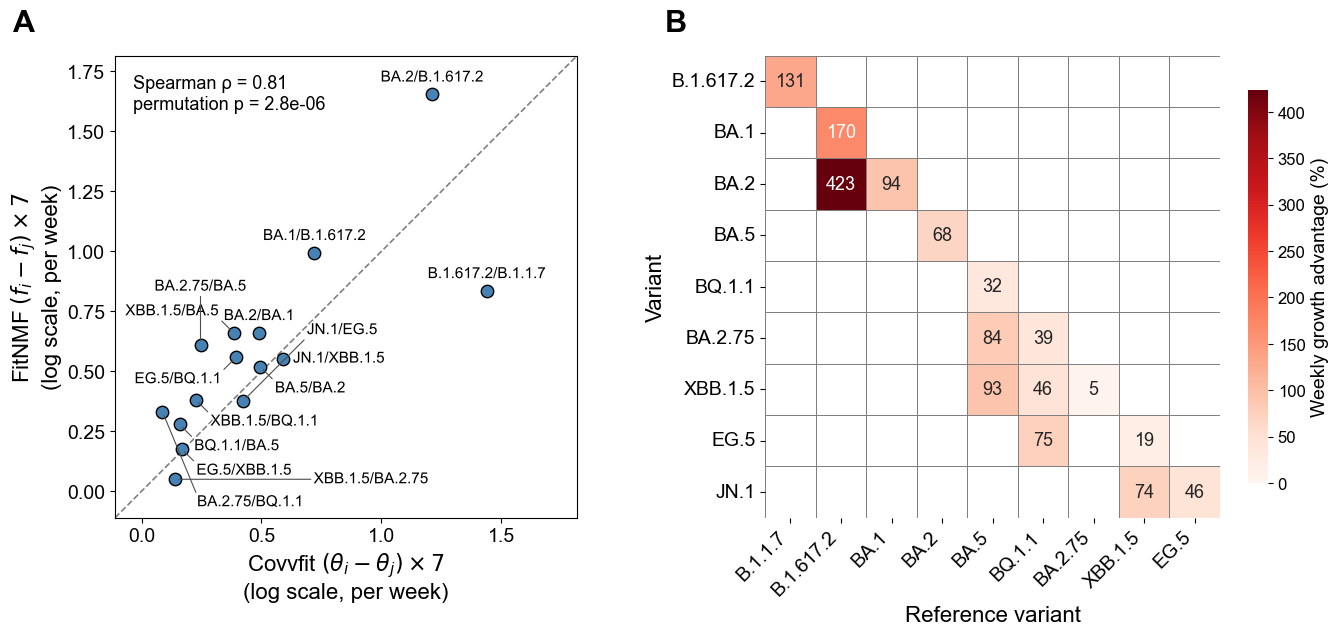

15 co-circulating pairs, 10 matched variants: Spearman rho = 0.811, two-sided permutation p = 2.8e-06 (3,628,800 permutations)


In [50]:
from evaluation.fig3_growth_advantages import make_figure3

stats = make_figure3(result_fitness, data, W_covspectrum,
                     covvfit_path=ROOT / 'results' / 'Covvfit_comparison' / 'results_covvfit',
                     out_dir=ROOT / 'results' / 'real_data')